# 01 — Data exploration & cleaning

**Goal:** understand the IBM Telco Customer Churn dataset, find data-quality issues, clean them, and explore what drives churn.

**Dataset:** 7,043 customers of a fictional telecom provider, 21 columns: demographics, subscribed services, contract/billing details, charges, and whether the customer churned (left) in the last month.

In [1]:
import sys
from pathlib import Path

# Make the src package importable when running from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 40)
FIG = PROJECT_ROOT / "reports" / "figures"

In [2]:
from src.data_cleaning import load_raw_data, clean_customers

raw = load_raw_data()
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges should be a number, but pandas read it as text ("object")
raw.dtypes.value_counts(), raw["TotalCharges"].dtype

(object     18
 int64       2
 float64     1
 Name: count, dtype: int64,
 dtype('O'))

## Data-quality issues

1. **`TotalCharges` is stored as text** — 11 rows contain a blank string instead of a number.
2. **`Churn` is text** (`Yes`/`No`) and must become 1/0 for modelling.
3. **`SeniorCitizen`** is the only demographic stored as 0/1 instead of `Yes`/`No`.

Let's look at the 11 blank `TotalCharges` rows — they all have `tenure = 0`. These are brand-new customers who haven't been billed yet, so the correct value is **0.0**, not a random missing value.

In [4]:
blanks = raw[pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()]
blanks[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [5]:
# No duplicate rows, and every customerID is unique
print("duplicate rows:", raw.duplicated().sum())
print("customerID unique:", raw["customerID"].is_unique)

duplicate rows: 0
customerID unique: True


In [6]:
clean = clean_customers(raw)   # fixes all three issues (see src/data_cleaning.py)
clean[["tenure", "MonthlyCharges", "TotalCharges", "churn"]].describe().round(2)

,tenure,MonthlyCharges,TotalCharges,churn
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.27
std,24.56,30.09,2266.79,0.44
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,0.00
75%,55.00,89.85,3786.60,1.00
max,72.00,118.75,8684.80,1.00


## Exploratory analysis

The cell below builds the engineered feature table and saves every chart to `reports/figures/` using the shared plotting code in `src/eda.py`, so the notebook and the pipeline always produce identical figures.

In [7]:
from src.feature_engineering import add_features
from src.eda import run_eda

features = add_features(clean)
run_eda(features)
print("Figures written to", FIG)

Figures written to c:\Users\cade_\OneDrive\Desktop\Projects\ML PROJECT\reports\figures


### Class balance — 26.5% of customers churned

About 1 in 4 customers leaves. The classes are imbalanced enough that **accuracy alone is misleading**: predicting "nobody churns" is already ~73.5% accurate but catches zero churners. That motivates recall, precision, ROC-AUC and PR-AUC later.

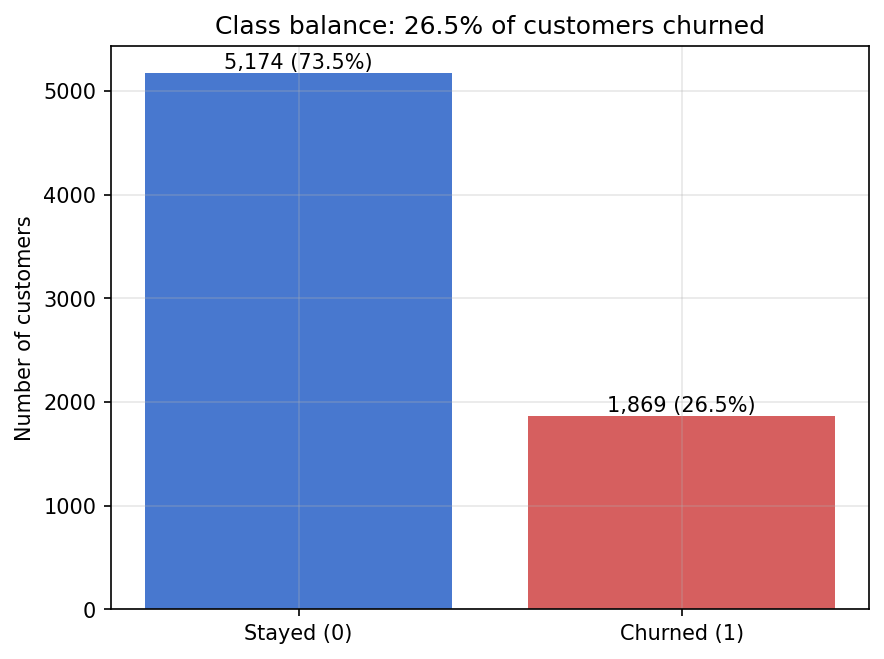

In [8]:
display(Image(filename=str(FIG / "01_churn_rate.png"), width=700))

### Contract type is the strongest single signal

Month-to-month customers churn at **42.7%**, one-year at **11.3%**, two-year at just **2.8%**. No lock-in means nothing stops an unhappy customer from leaving this month.

**Business insight:** converting month-to-month customers to annual contracts is the most direct retention lever.

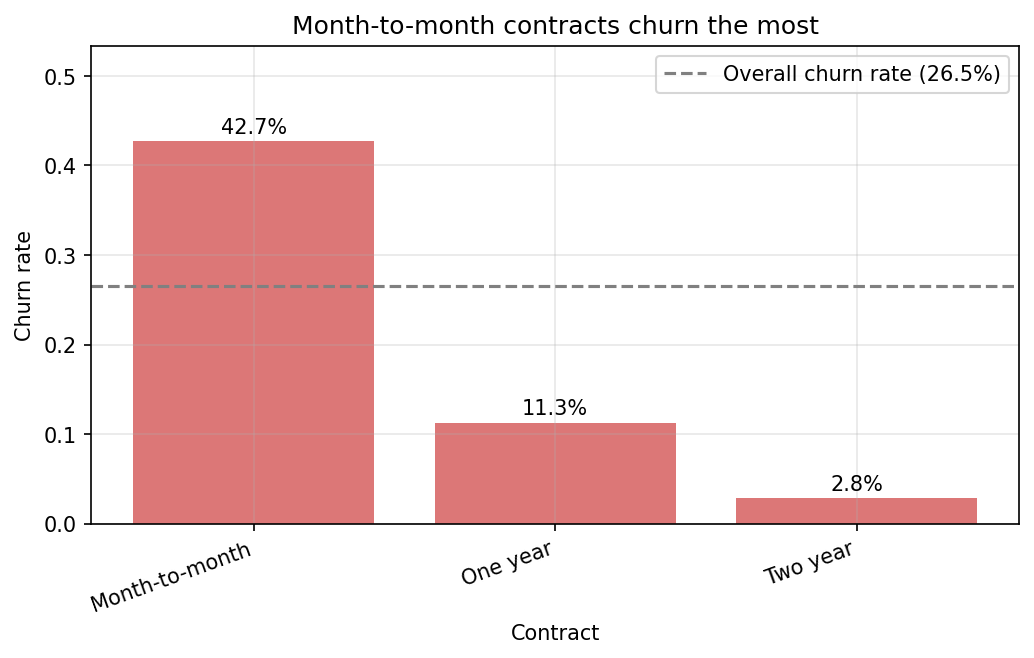

In [9]:
display(Image(filename=str(FIG / "02_churn_by_contract.png"), width=700))

### New customers are the riskiest

Churn falls from **47.4%** in the first year to **9.5%** for customers with 4+ years of tenure. The first 12 months are the danger zone — onboarding experience matters.

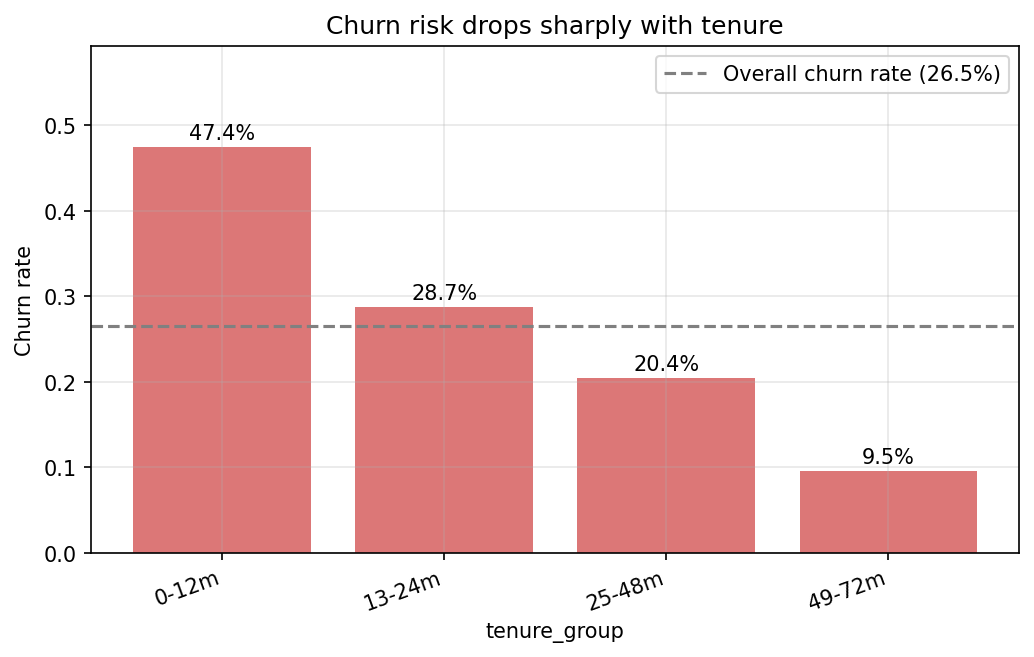

In [10]:
display(Image(filename=str(FIG / "03_churn_by_tenure_group.png"), width=700))

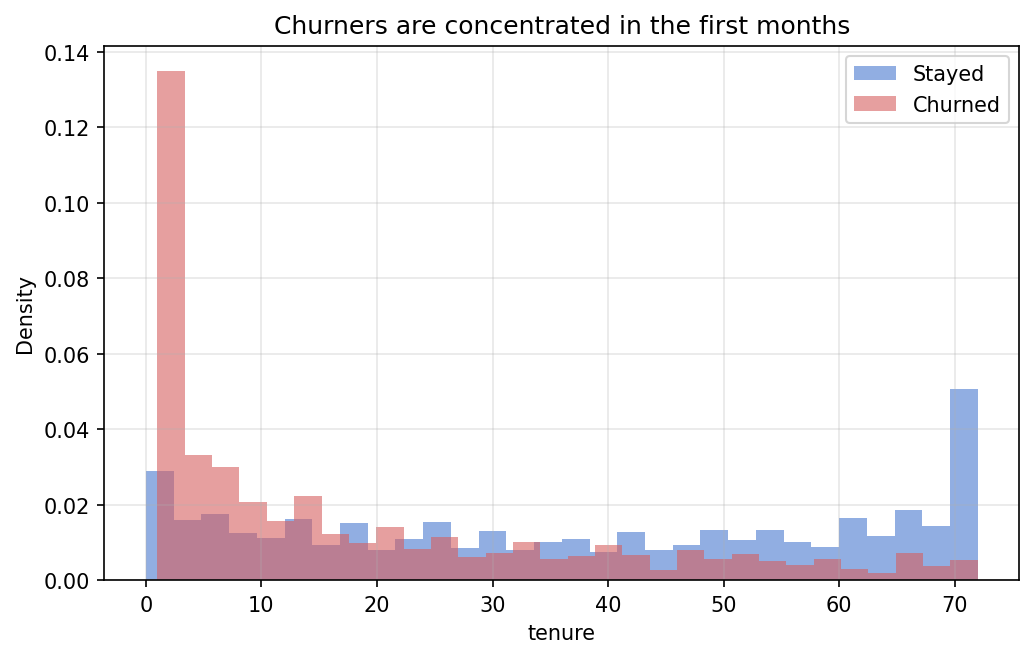

In [11]:
display(Image(filename=str(FIG / "04_tenure_distribution.png"), width=700))

### Higher bills, higher churn

Churners cluster at **higher monthly charges** (roughly $70–100). Price-sensitive customers on expensive plans are a clear risk segment.

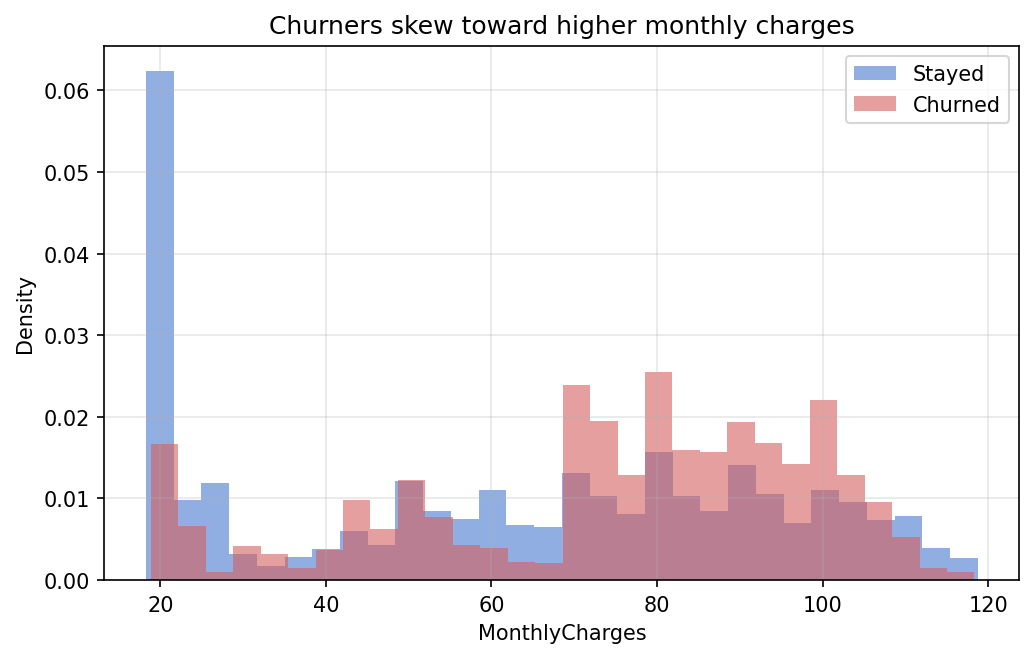

In [12]:
display(Image(filename=str(FIG / "05_monthly_charges_distribution.png"), width=700))

### Payment method: electronic checks stand out

Electronic-check payers churn at **45.3%**, versus ~15–17% for automatic bank transfer / credit card. Manual payment creates a monthly decision point — and may proxy for customers who avoid commitment.

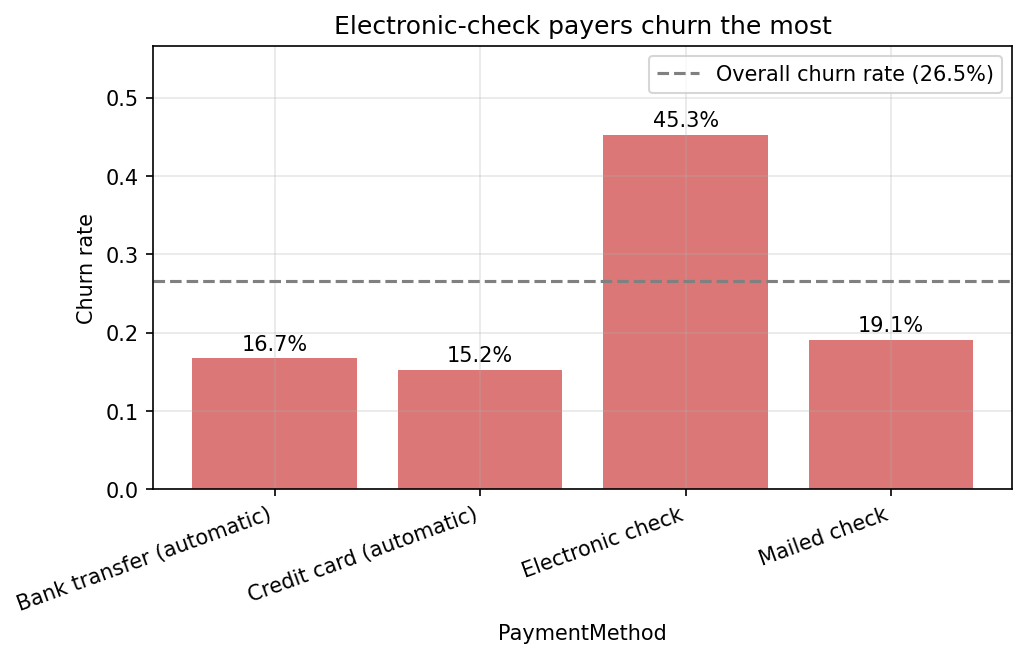

In [13]:
display(Image(filename=str(FIG / "06_churn_by_payment_method.png"), width=700))

### Fiber-optic customers churn the most

Fiber customers churn at **41.9%** vs **19.0%** for DSL and **7.4%** for no internet. Fiber is the premium (most expensive) product — this pattern suggests a price/expectation problem in the fiber segment.

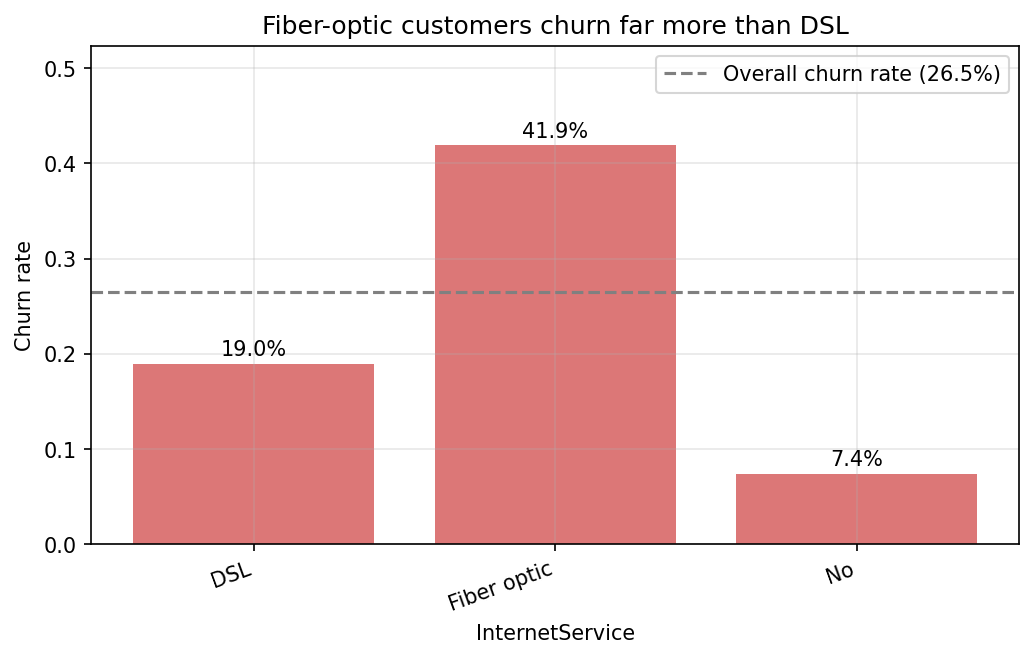

In [14]:
display(Image(filename=str(FIG / "07_churn_by_internet_service.png"), width=700))

### Senior citizens churn more

Seniors churn at **41.7%** vs **23.6%** for non-seniors — a smaller segment (~16% of customers) but a clearly elevated risk.

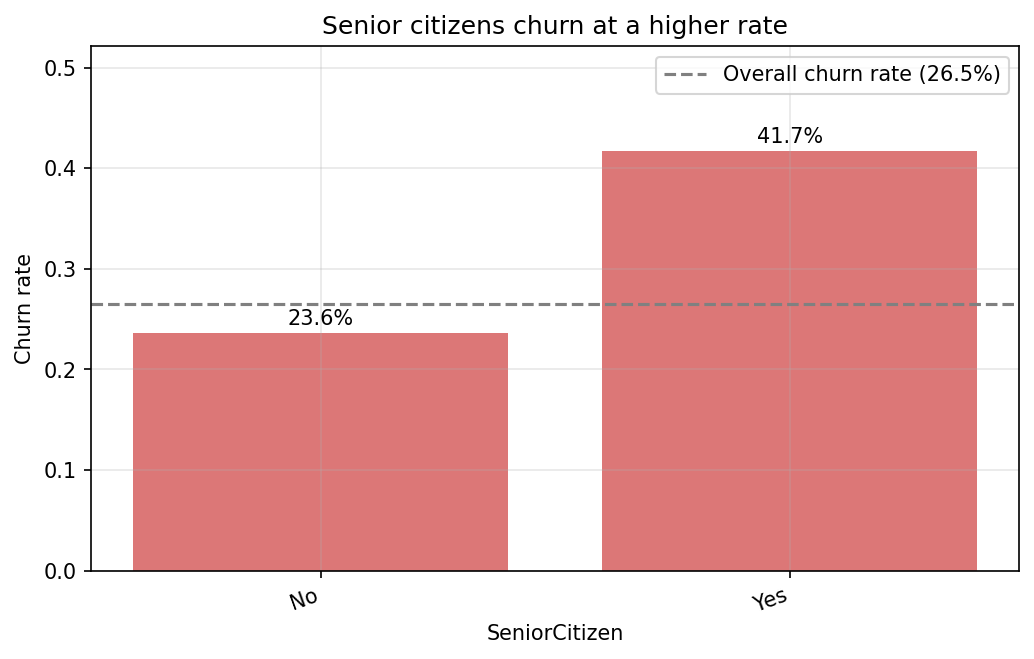

In [15]:
display(Image(filename=str(FIG / "08_churn_by_senior_citizen.png"), width=700))

### Numeric relationships

`tenure` and `TotalCharges` are strongly correlated (long-tenured customers have paid more in total) — worth remembering when interpreting model coefficients. `tenure` correlates **negatively** with churn; `MonthlyCharges` positively.

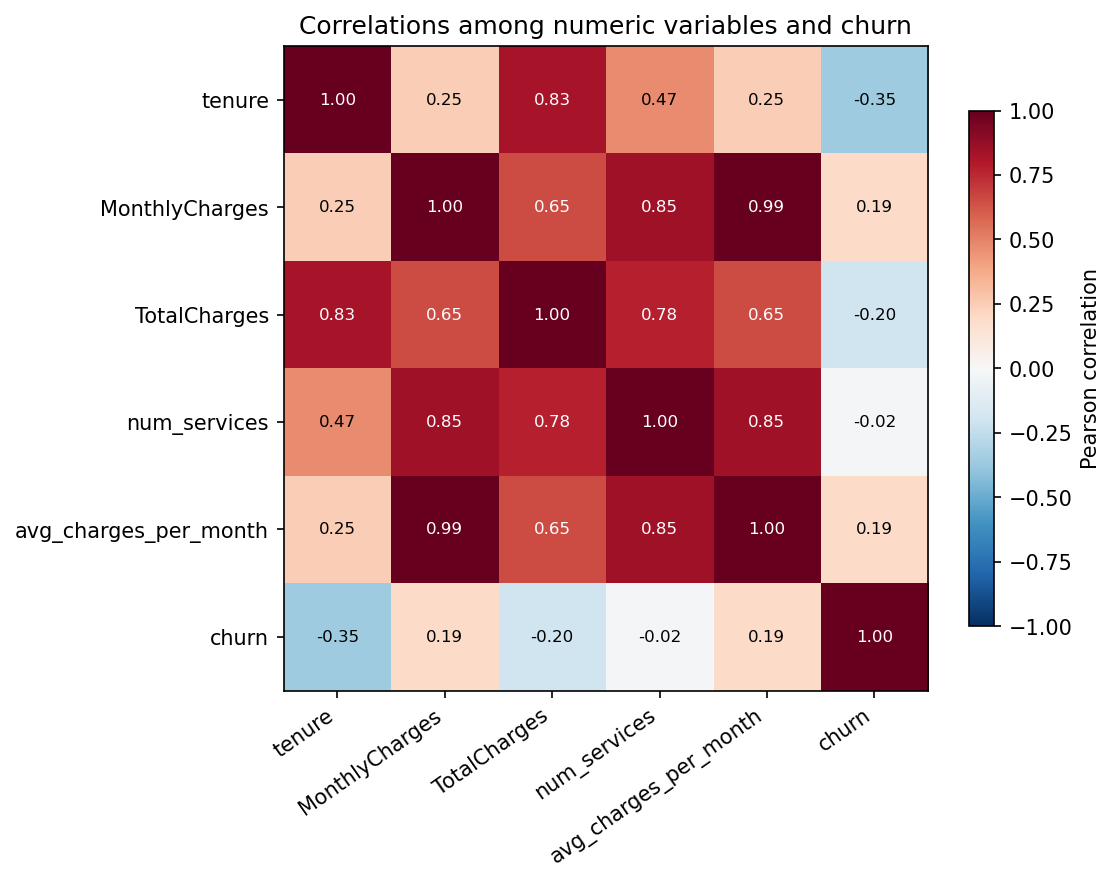

In [16]:
display(Image(filename=str(FIG / "09_numeric_correlations.png"), width=700))

## Key takeaways

1. The dataset is clean apart from the `TotalCharges` text/blank issue (11 tenure-0 rows → 0.0).
2. Churn concentrates in: month-to-month contracts, first-year customers, electronic-check payers, fiber-optic subscribers, and high monthly bills.
3. Class imbalance (26.5% churn) means evaluation must go beyond accuracy.

Next: `02_feature_engineering.ipynb` turns these patterns into model features.